In [ ]:
!curl -L -o raf-db-dataset.zip\
  https://www.kaggle.com/api/v1/datasets/download/shuvoalok/raf-db-dataset

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 37.6M  100 37.6M    0     0  40.7M      0 --:--:-- --:--:-- --:--:-- 75.7M


In [ ]:
!unzip raf-db-dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: DATASET/train/5/train_00987_aligned.jpg  
  inflating: DATASET/train/5/train_00990_aligned.jpg  
  inflating: DATASET/train/5/train_00991_aligned.jpg  
  inflating: DATASET/train/5/train_00992_aligned.jpg  
  inflating: DATASET/train/5/train_01002_aligned.jpg  
  inflating: DATASET/train/5/train_01010_aligned.jpg  
  inflating: DATASET/train/5/train_01011_aligned.jpg  
  inflating: DATASET/train/5/train_01013_aligned.jpg  
  inflating: DATASET/train/5/train_01015_aligned.jpg  
  inflating: DATASET/train/5/train_01017_aligned.jpg  
  inflating: DATASET/train/5/train_01039_aligned.jpg  
  inflating: DATASET/train/5/train_01048_aligned.jpg  
  inflating: DATASET/train/5/train_01049_aligned.jpg  
  inflating: DATASET/train/5/train_01053_aligned.jpg  
  inflating: DATASET/train/5/train_01070_aligned.jpg  
  inflating: DATASET/train/5/train_01074_aligned.jpg  
  inflating: DATASET/train/5/train_01078_aligned.jpg  
  inflating: D

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os

def show_class_images(
    csv_path,
    image_dir,
    target_label,
    label_col="label",
    filename_col="image",
    n_images=10,
    cols=5,
    grayscale=False,
    random_state=42,
):
    df = pd.read_csv(csv_path)
    subset = df[df[label_col] == target_label]

    if len(subset) == 0:
        print(f"No images found for label {target_label}")
        return

    n = min(n_images, len(subset))
    subset = subset.sample(n=n, random_state=random_state)

    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, subset.iterrows()):
        img_path = os.path.join(image_dir, str(target_label), row[filename_col])
        img = Image.open(img_path)
        ax.imshow(img, cmap="gray" if grayscale else None)
        ax.set_title(f"{row[filename_col]}", fontsize=8)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.suptitle(f"Class label: {target_label}")
    plt.tight_layout()
    plt.show()

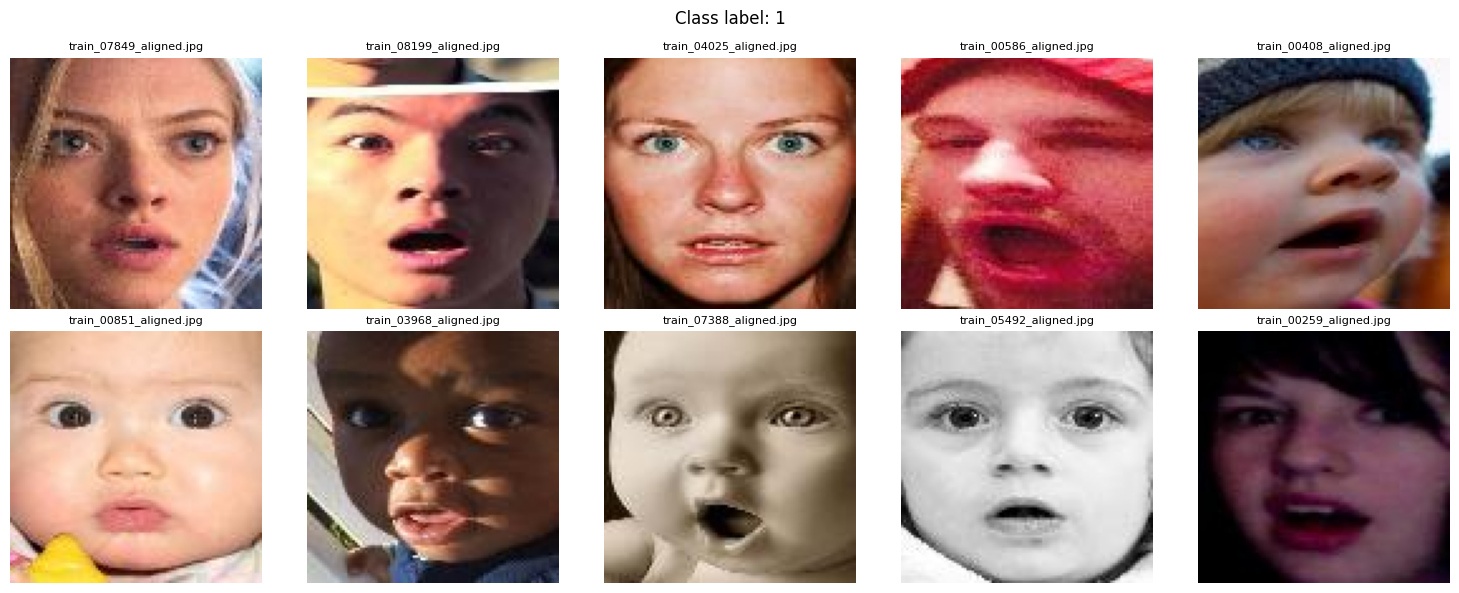

In [ ]:
csv_path = "train_labels.csv"
images_dir = "DATASET/train/"

show_class_images(csv_path, images_dir, 1)
## SURPRISE

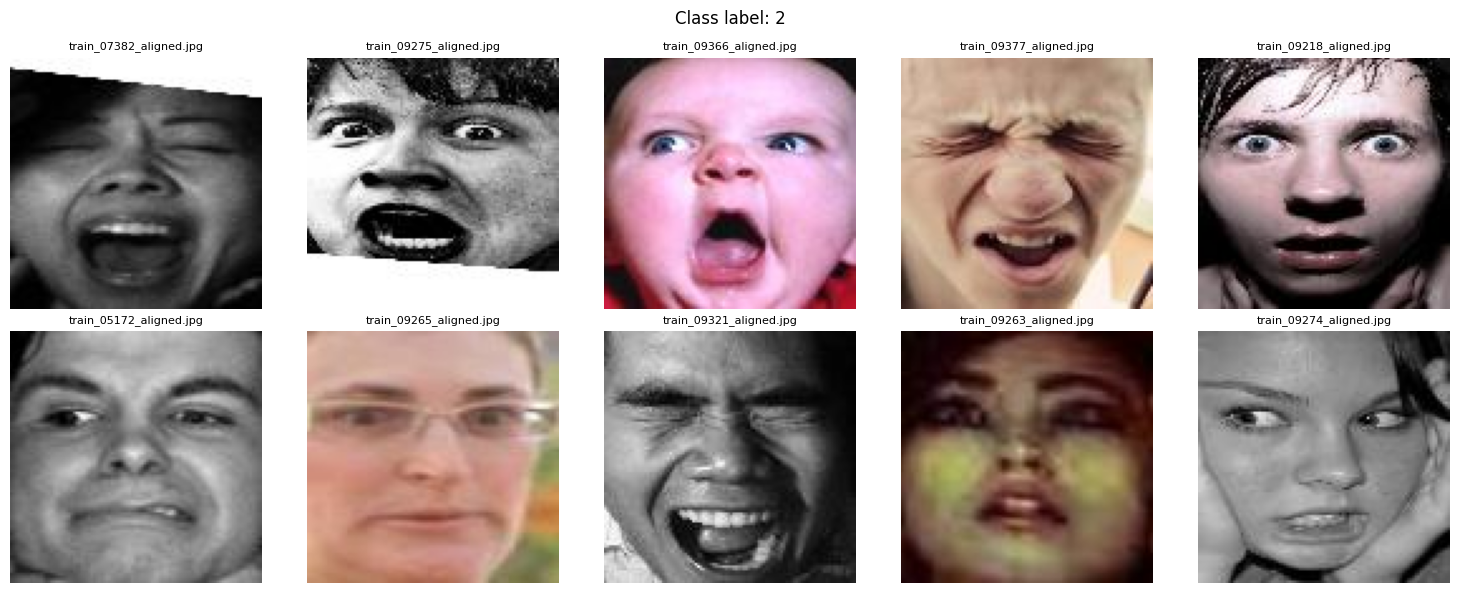

In [ ]:
show_class_images(csv_path, images_dir, 2)
## FEAR

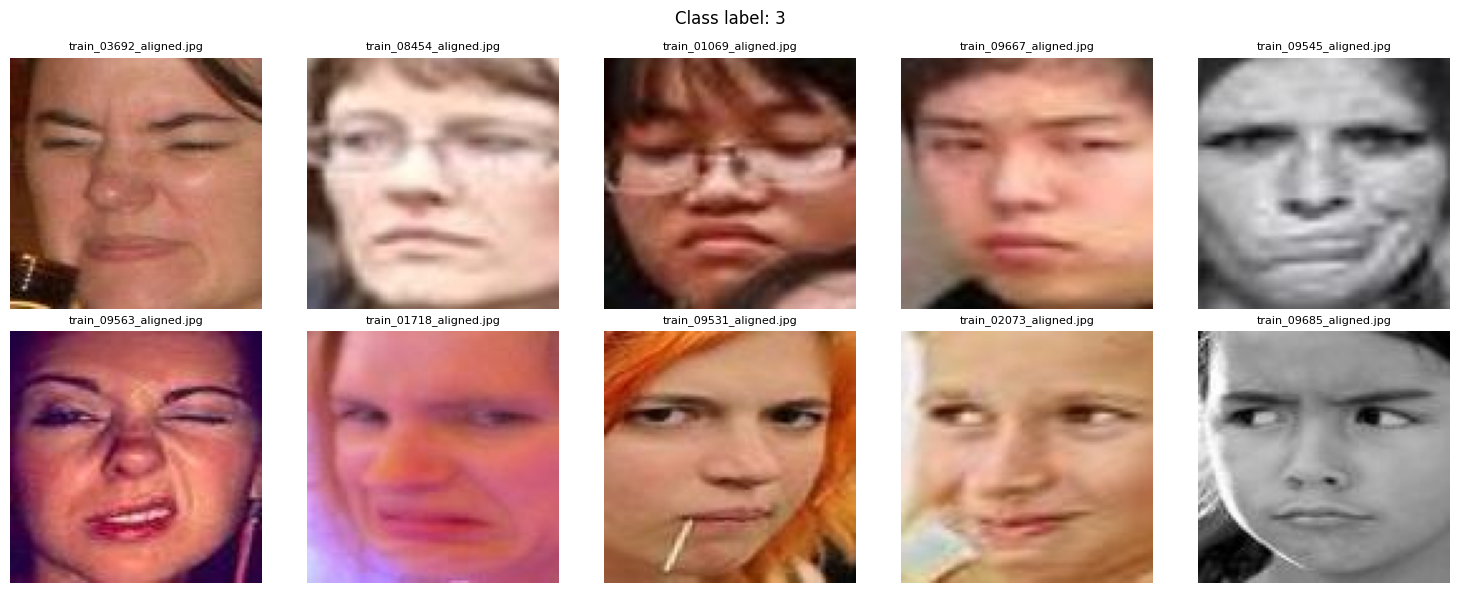

In [ ]:
show_class_images(csv_path, images_dir, 3)
## DISGUST

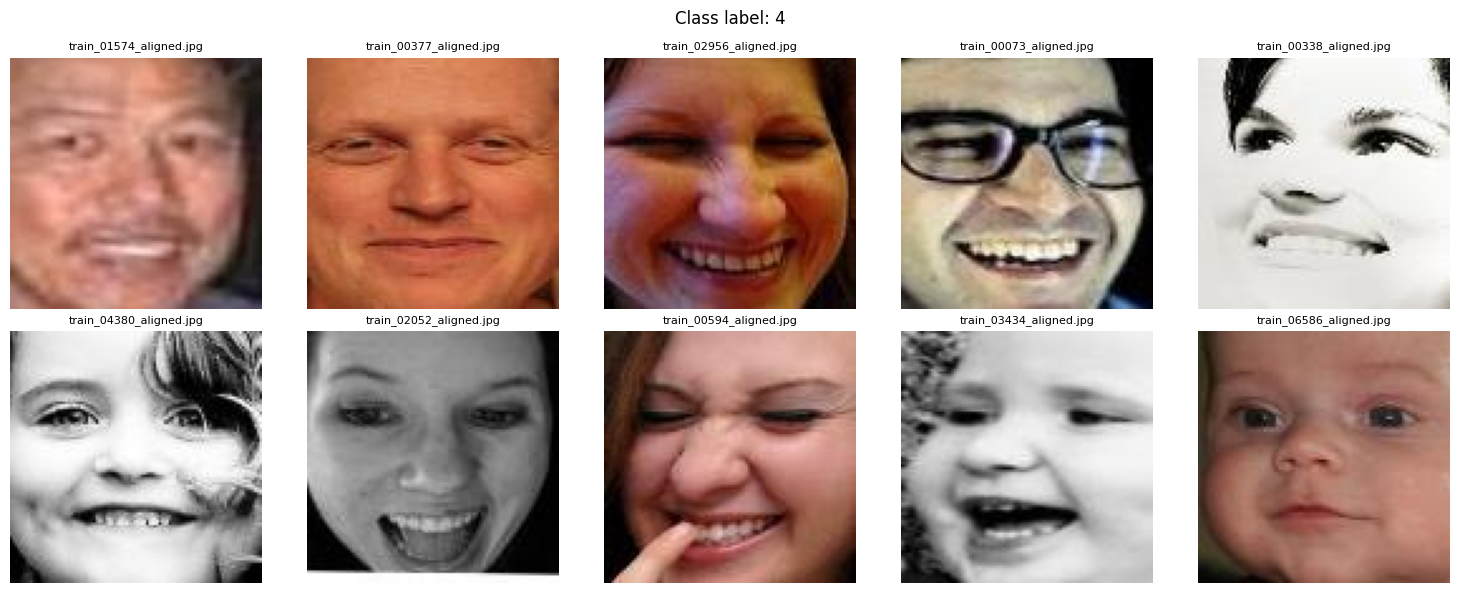

In [ ]:
show_class_images(csv_path, images_dir, 4)
## HAPPINESS

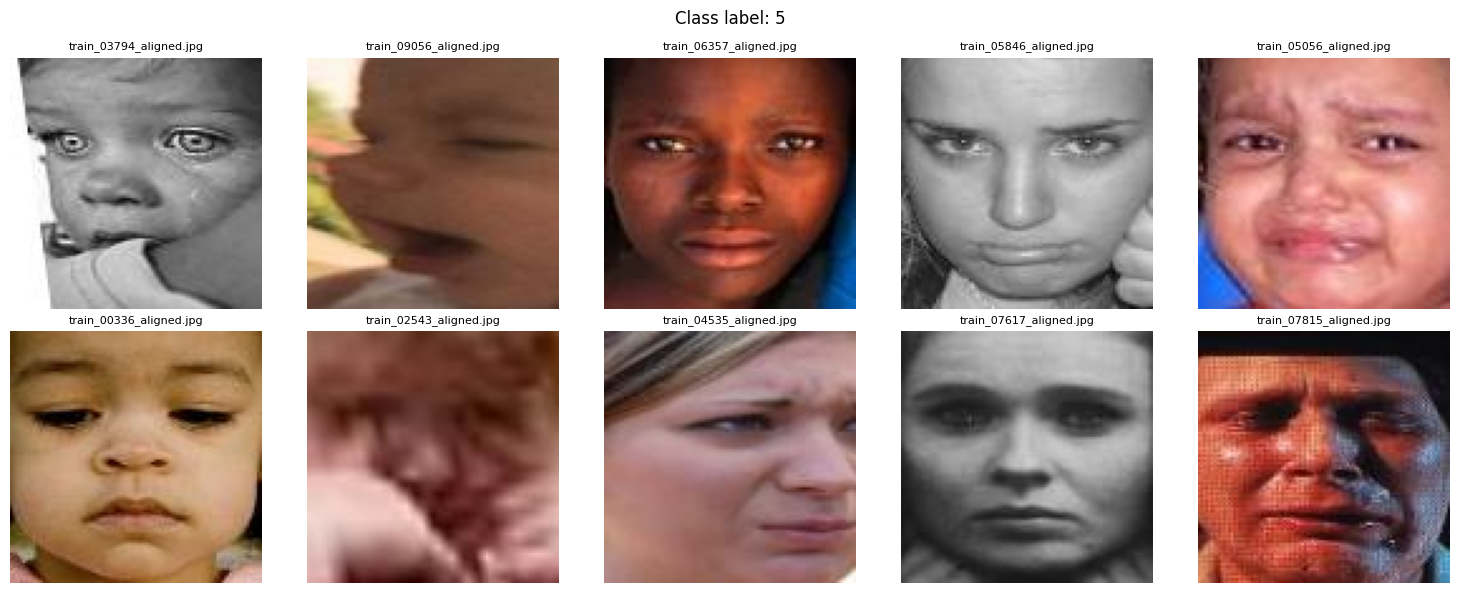

In [ ]:
show_class_images(csv_path, images_dir, 5)
## SADNESS

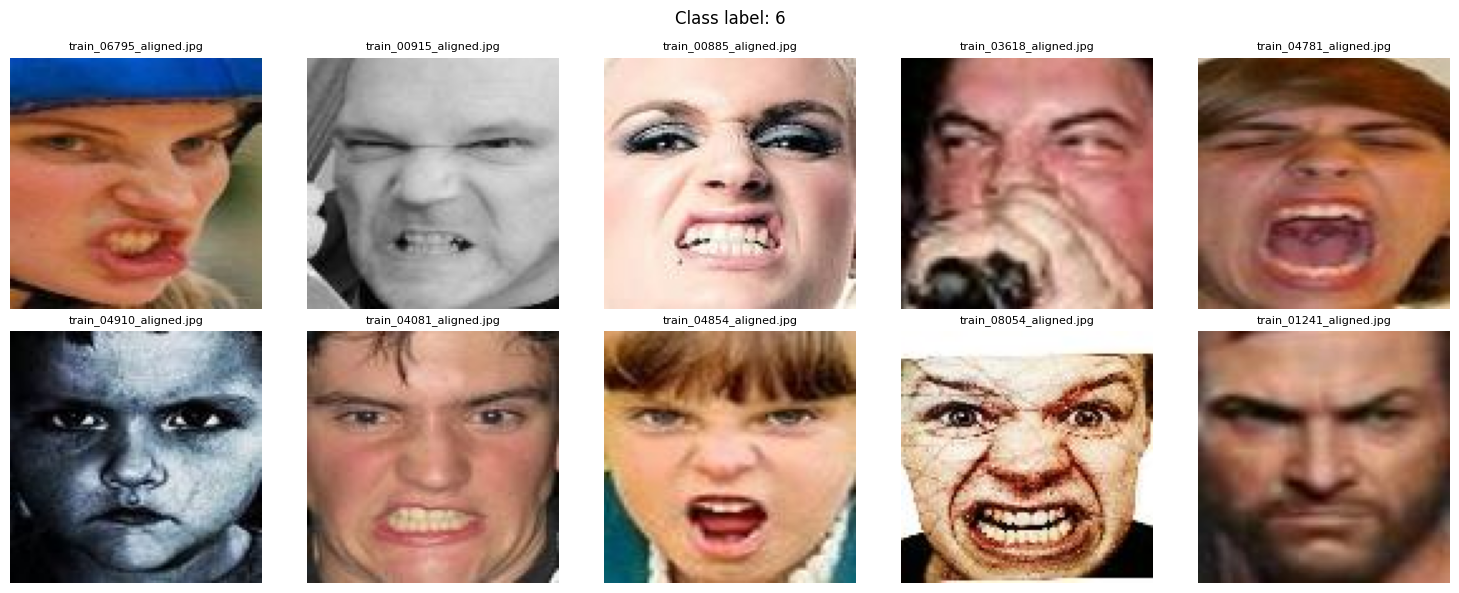

In [ ]:
show_class_images(csv_path, images_dir, 6)
## ANGER

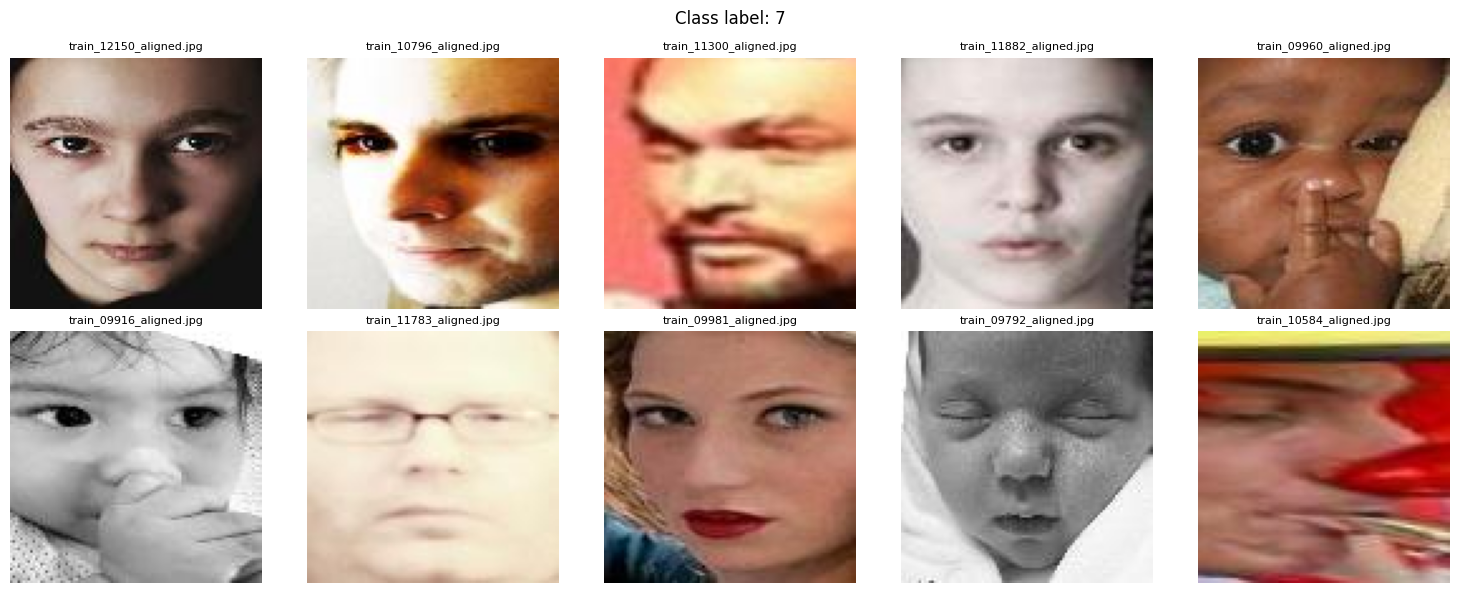

In [ ]:
show_class_images(csv_path, images_dir, 7)
## NEUTRAL

In [ ]:
import os

# --- config ---
dataset_root = "/content/DATASET"   # folder containing train/ and test/

# 1. rename test -> val
test_path = os.path.join(dataset_root, "test")
val_path = os.path.join(dataset_root, "val")

if os.path.exists(test_path):
    os.rename(test_path, val_path)
    print(f"Renamed: {test_path} -> {val_path}")
else:
    print("No 'test' folder found — skipping.")

# 2. rename numeric label folders -> textual labels, inside train/ and val/
label_map = {
    "1": "surprise",
    "2": "fear",
    "3": "disgust",
    "4": "happiness",
    "5": "sadness",
    "6": "anger",
    "7": "neutral",
}

for split in ["train", "val"]:
    split_path = os.path.join(dataset_root, split)
    if not os.path.isdir(split_path):
        continue

    for old_name in os.listdir(split_path):
        old_full = os.path.join(split_path, old_name)
        if not os.path.isdir(old_full):
            continue

        if old_name in label_map:
            new_full = os.path.join(split_path, label_map[old_name])
            os.rename(old_full, new_full)
            print(f"{split}: {old_name} -> {label_map[old_name]}")
        else:
            print(f"{split}: '{old_name}' not found in label_map, left unchanged")

Renamed: /content/DATASET/test -> /content/DATASET/val
train: 4 -> happiness
train: 2 -> fear
train: 7 -> neutral
train: 3 -> disgust
train: 1 -> surprise
train: 6 -> anger
train: 5 -> sadness
val: 4 -> happiness
val: 2 -> fear
val: 7 -> neutral
val: 3 -> disgust
val: 1 -> surprise
val: 6 -> anger
val: 5 -> sadness


In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 9.1 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

# Load a model
model = YOLO("yolo26n-cls.pt")  # load a pretrained model (recommended for training)

# Train the model
results = model.train(data="DATASET", epochs=40, imgsz=128, batch=128)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=128, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=DATASET, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.

In [ ]:
!zip -r runs.zip runs/
from google.colab import files
files.download('runs.zip')

updating: runs/ (stored 0%)
updating: runs/classify/ (stored 0%)
updating: runs/classify/train/ (stored 0%)
updating: runs/classify/train/results.csv (deflated 66%)
updating: runs/classify/train/train_batch1.jpg (deflated 4%)
updating: runs/classify/train/val_batch2_pred.jpg (deflated 1%)
updating: runs/classify/train/confusion_matrix_normalized.png (deflated 18%)
updating: runs/classify/train/val_batch1_pred.jpg (deflated 1%)
updating: runs/classify/train/weights/ (stored 0%)
updating: runs/classify/train/weights/best.pt (deflated 9%)
updating: runs/classify/train/weights/last.pt (deflated 9%)
updating: runs/classify/train/val_batch1_labels.jpg (deflated 1%)
updating: runs/classify/train/results.png (deflated 9%)
updating: runs/classify/train/val_batch2_labels.jpg (deflated 1%)
updating: runs/classify/train/train_batch2880.jpg (deflated 3%)
updating: runs/classify/train/confusion_matrix.png (deflated 22%)
updating: runs/classify/train/train_batch2.jpg (deflated 2%)
updating: runs/clas

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>